In [56]:
import pandas as pd 
df=pd.read_csv(r'C:\Users\Homes\OneDrive\Desktop\Fake_job_posting_detector\fake_job_postings.csv')
df.columns.tolist()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [57]:
import pandas as pd
import numpy as np
import sklearn
import nltk

print("Fake Job Detector Environment Ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Fake Job Detector Environment Ready!
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


In [58]:
df.isnull().sum()

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

In [59]:
df['fraudulent'].value_counts()


fraudulent
0    17014
1      866
Name: count, dtype: int64

In [60]:
df['fraudulent'].value_counts(normalize=True) * 100


fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64

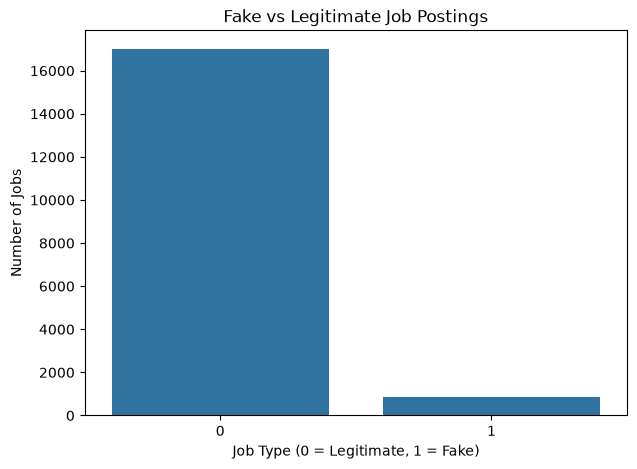

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='fraudulent')

plt.title('Fake vs Legitimate Job Postings')
plt.xlabel('Job Type (0 = Legitimate, 1 = Fake)')
plt.ylabel('Number of Jobs')

plt.show()

In [62]:
fake = df['fraudulent'].value_counts()

print("Legitimate jobs:", fake.get(0, 0))
print("Fake jobs:", fake.get(1, 0))
print("Imbalance ratio:", round(fake.get(0, 0) / fake.get(1, 1), 2))

Legitimate jobs: 17014
Fake jobs: 866
Imbalance ratio: 19.65


In [63]:
text_columns = [
    'title',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

df[text_columns].head()

,title,company_profile,description,requirements,benefits
0,Marketing Intern,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...
2,Commissioning Machinery Assistant (CMA),Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN
3,Account Executive - Washington DC,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...
4,Bill Review Manager,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered


In [64]:
for col in text_columns:
    df[col] = df[col].fillna('').astype(str)

df['combined_text'] = df[text_columns].agg(' '.join, axis=1)

In [65]:
df[['combined_text', 'fraudulent']].head()

,combined_text,fraudulent
0,"Marketing Intern We're Food52, and we've creat...",0
1,Customer Service - Cloud Video Production 90 S...,0
2,Commissioning Machinery Assistant (CMA) Valor ...,0
3,Account Executive - Washington DC Our passion ...,0
4,Bill Review Manager SpotSource Solutions LLC i...,0


In [66]:
df['text_length'] = df['combined_text'].apply(len)

df['text_length'].describe()

count    17880.000000
mean      2670.464094
std       1465.514148
min         18.000000
25%       1595.000000
50%       2522.000000
75%       3475.000000
max      14945.000000
Name: text_length, dtype: float64

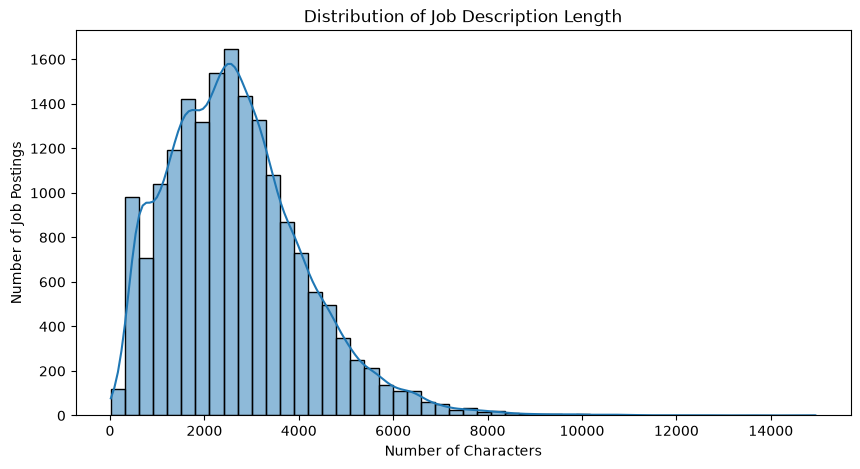

In [67]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='text_length',
    bins=50,
    kde=True
)

plt.title('Distribution of Job Description Length')
plt.xlabel('Number of Characters')
plt.ylabel('Number of Job Postings')

plt.show()

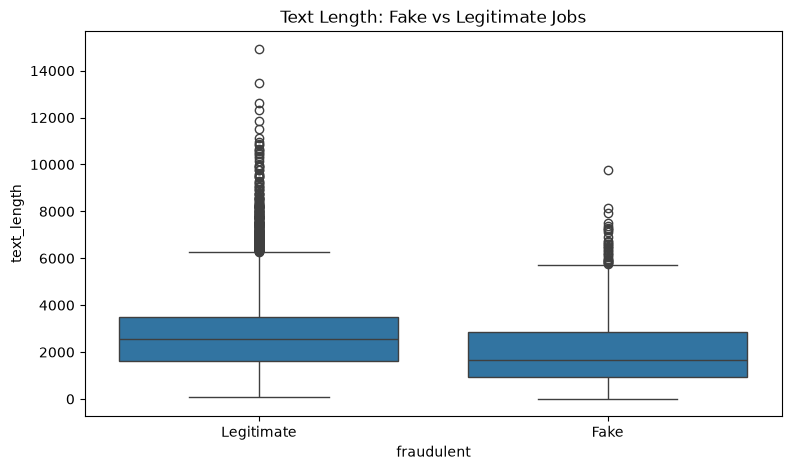

In [68]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='fraudulent',
    y='text_length'
)

plt.xticks([0, 1], ['Legitimate', 'Fake'])
plt.title('Text Length: Fake vs Legitimate Jobs')

plt.show()

In [69]:
from sklearn.model_selection import train_test_split

X = df['combined_text']
y = df['fraudulent']

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [71]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 14304
Testing samples: 3576

Training distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Testing distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64


In [72]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=30000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [73]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (14304, 30000)
Testing TF-IDF shape: (3576, 30000)
Vocabulary size: 30000


In [74]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [75]:
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Predictions completed!")
print("Total predictions:", len(y_pred_lr))

Predictions completed!
Total predictions: 3576


In [76]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Legitimate', 'Fake'],
    zero_division=0
))

              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99      3403
        Fake       0.77      0.91      0.83       173

    accuracy                           0.98      3576
   macro avg       0.88      0.95      0.91      3576
weighted avg       0.98      0.98      0.98      3576



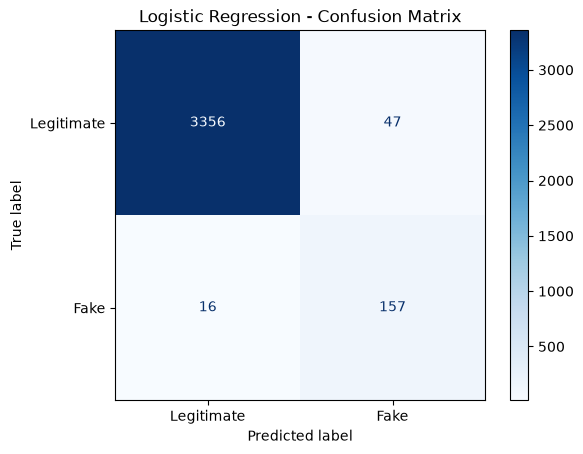

[[3356   47]
 [  16  157]]


In [77]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fake']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

print(cm)

In [78]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [79]:
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes predictions completed!")
print("Total predictions:", len(y_pred_nb))

Naive Bayes predictions completed!
Total predictions: 3576


In [80]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Legitimate', 'Fake'],
    zero_division=0
))

              precision    recall  f1-score   support

  Legitimate       0.97      0.99      0.98      3403
        Fake       0.69      0.38      0.49       173

    accuracy                           0.96      3576
   macro avg       0.83      0.69      0.74      3576
weighted avg       0.96      0.96      0.96      3576



In [81]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, pos_label=1),
        precision_score(y_test, y_pred_nb, pos_label=1)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, pos_label=1),
        recall_score(y_test, y_pred_nb, pos_label=1)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, pos_label=1),
        f1_score(y_test, y_pred_nb, pos_label=1)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.982383,0.769608,0.907514,0.832891
1,Naive Bayes,0.961969,0.694737,0.381503,0.492537


In [82]:
import joblib
joblib.dump(lr_model, "fake_job_model.pkl")

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


In [83]:
import os

print(os.path.exists("fake_job_model.pkl"))
print(os.path.exists("tfidf_vectorizer.pkl"))

True
True
